# Assignment 08 - Part 2: Convolutional Neural Network (CNN) for Cat and Dog Classification
**Course:** ECE 5831 - Pattern Recognition and Neural Networks  
**Author:** Michel Temgoua  

## Overview
This notebook builds, trains, and evaluates a deep Convolutional Neural Network (CNN) from scratch using Keras to classify images of cats and dogs from the dataset provided.
It also automatically unpacks data_from_kaggle.zip and partitions the images into an 80/20 train/validation split, while preserving the test set structure.

In [1]:
import os
import shutil
import random
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.utils import image_dataset_from_directory
import matplotlib.pyplot as plt

# Unpack dataset archive if not already extracted
if not os.path.exists("data_from_kaggle"):
    shutil.unpack_archive("data_from_kaggle.zip")

source_path = "data_from_kaggle"
output_path = "dataset"
train_ratio = 0.8
random.seed(42)

# Create directory hierarchy for train, validation, and test splits
for split in ["train", "validation", "test"]:
    for class_name in ["dog", "cat"]:
        folder = os.path.join(output_path, split, class_name)
        os.makedirs(folder, exist_ok=True)

# Organize files into splits
train_source = os.path.join(source_path, "train")
test_source = os.path.join(source_path, "test")

cat_imgs = [f for f in os.listdir(train_source) if f.lower().startswith("cat")]
dog_imgs = [f for f in os.listdir(train_source) if f.lower().startswith("dog")]
test_cat_imgs = [f for f in os.listdir(test_source) if f.lower().startswith("cat")]
test_dog_imgs = [f for f in os.listdir(test_source) if f.lower().startswith("dog")]

random.shuffle(cat_imgs)
random.shuffle(dog_imgs)

cat_split = int(len(cat_imgs) * train_ratio)
dog_split = int(len(dog_imgs) * train_ratio)

# Copy files to respective train/validation directories
for f in cat_imgs[:cat_split]:
    shutil.copy(os.path.join(train_source, f), os.path.join(output_path, "train", "cat", f))
for f in dog_imgs[:dog_split]:
    shutil.copy(os.path.join(train_source, f), os.path.join(output_path, "train", "dog", f))
for f in cat_imgs[cat_split:]:
    shutil.copy(os.path.join(train_source, f), os.path.join(output_path, "validation", "cat", f))
for f in dog_imgs[dog_split:]:
    shutil.copy(os.path.join(train_source, f), os.path.join(output_path, "validation", "dog", f))

for f in test_cat_imgs:
    shutil.copy(os.path.join(test_source, f), os.path.join(output_path, "test", "cat", f))
for f in test_dog_imgs:
    shutil.copy(os.path.join(test_source, f), os.path.join(output_path, "test", "dog", f))

print("Dataset successfully structured into train, validation, and test directories.")

Dataset successfully structured into train, validation, and test directories.


## Defines a 5-layer Convolutional Neural Network with alternating Conv2D feature extractors and MaxPooling2D downsampling layers, followed by a flattening layer and a binary Sigmoid output neuron.

In [2]:
def build_cnn_model():
    inputs = keras.Input(shape=(200, 180, 3))
    x = layers.Rescaling(1./255)(inputs)
    
    # Convolutional & MaxPooling Blocks
    x = layers.Conv2D(filters=32, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    
    x = layers.Conv2D(filters=64, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    
    x = layers.Conv2D(filters=128, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    
    x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    
    x = layers.Conv2D(filters=256, kernel_size=3, activation="relu")(x)
    x = layers.MaxPooling2D(pool_size=2)(x)
    
    # Classification Head
    x = layers.Flatten()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    
    model = keras.Model(inputs=inputs, outputs=outputs)
    return model

model = build_cnn_model()
model.summary()

model.compile(
    loss="binary_crossentropy",
    optimizer="rmsprop",
    metrics=["accuracy"]
)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 200, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 200, 180, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 198, 178, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 99, 89, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 97, 87, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 48, 43, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 46, 41, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 23, 20, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 21, 18, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 10, 9, 256)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 7, 256)      │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 4, 3, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3072)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         3,073 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 981,569 (3.74 MB)

 Trainable params: 981,569 (3.74 MB)

 Non-trainable params: 0 (0.00 B)

## Loads images dynamically in batches of 32 resized to $200 \times 180$ and trains the CNN for 10 epochs.

In [3]:
# Load image datasets from directories using Keras utility
train_dataset = image_dataset_from_directory("dataset/train", image_size=(200, 180), batch_size=32)
val_dataset = image_dataset_from_directory("dataset/validation", image_size=(200, 180), batch_size=32)
test_dataset = image_dataset_from_directory("dataset/test", image_size=(200, 180), batch_size=32)

# Train model for 10 epochs
history_cnn = model.fit(
    train_dataset, 
    epochs=10, 
    validation_data=val_dataset
)

Found 15991 files belonging to 2 classes.
Found 3998 files belonging to 2 classes.
Found 5000 files belonging to 2 classes.
Epoch 1/10


c:\Users\Michel Temgoua\anaconda3\envs\ece-5831-2026\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


500/500 ━━━━━━━━━━━━━━━━━━━━ 294s 584ms/step - accuracy: 0.6213 - loss: 0.6421 - val_accuracy: 0.7299 - val_loss: 0.5474
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 284s 567ms/step - accuracy: 0.7404 - loss: 0.5208 - val_accuracy: 0.7664 - val_loss: 0.4980
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 283s 567ms/step - accuracy: 0.7998 - loss: 0.4286 - val_accuracy: 0.8167 - val_loss: 0.4038
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 291s 582ms/step - accuracy: 0.8507 - loss: 0.3401 - val_accuracy: 0.8607 - val_loss: 0.3100
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 317s 634ms/step - accuracy: 0.8757 - loss: 0.2820 - val_accuracy: 0.8832 - val_loss: 0.2763
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 295s 589ms/step - accuracy: 0.9068 - loss: 0.2218 - val_accuracy: 0.8769 - val_loss: 0.3063
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 306s 612ms/step - accuracy: 0.9281 - loss: 0.1761 - val_accuracy: 0.8989 - val_loss: 0.2858
Epoch 8/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 327s 653ms/step - accuracy: 0.9446 - loss: 0.13

# Evaluates test batch images and plots a grid of 10 sample predictions, comparing the ground-truth label against the model's prediction.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 384ms/step


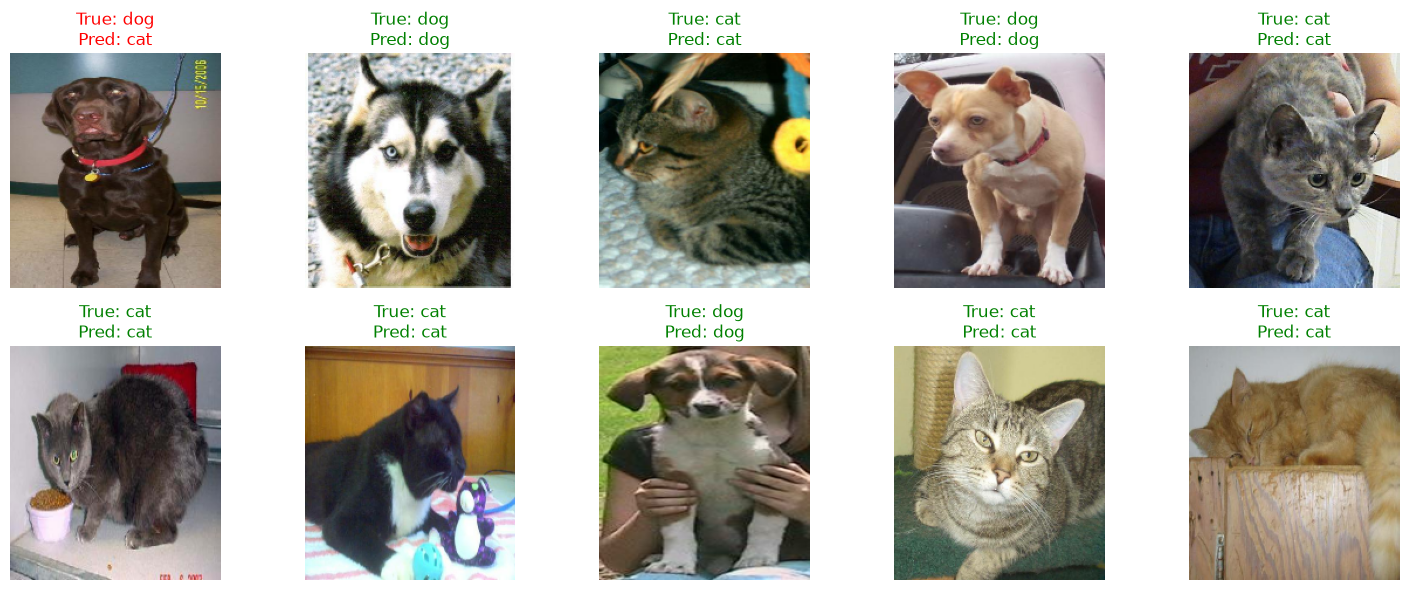

In [4]:
class_names = test_dataset.class_names  # ['cat', 'dog']

for imgs, labels in test_dataset.take(1):
    predictions = model.predict(imgs)
    pred_labels = (predictions > 0.5).astype(int).flatten()
    
    plt.figure(figsize=(15, 6))
    for i in range(10):
        plt.subplot(2, 5, i + 1)
        plt.imshow(imgs[i].numpy().astype("uint8"))
        true_class = class_names[int(labels[i])]
        pred_class = class_names[pred_labels[i]]
        
        color = "green" if true_class == pred_class else "red"
        plt.title(f"True: {true_class}\nPred: {pred_class}", color=color)
        plt.axis("off")
    plt.tight_layout()
    plt.show()